# SysCon 2027 experiment, step by step

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anonimoustt/IEEESyscon_2027/blob/main/syscon2027_experiment_walkthrough.ipynb)

This notebook reproduces Section IV of the paper *Model Specific Trustworthiness Debt in Learning Enabled Systems Using an Ontology*.
Each section matches one part of the paper, and the code is the same as `code/ontology_monitor.py` in the repository, split into small steps you can inspect.

What it does:

1. loads the NOAA weather data and splits it into 50 years of 360 days;
2. reads the model settings, the metric links, and the debts from the ontology with the SPARQL queries Q2, Q3, and Q7;
3. trains `MLP_Weather` on years 1 to 5;
4. computes the ten metrics of Table IV for one year;
5. builds resampled years from years 6 to 10 and sets the thresholds;
6. validates the thresholds on 5,000 new resampled years;
7. monitors years 11 to 50 with the debt rule;
8. repeats everything for `LR_Weather`;
9. compares every key number with the paper.

Run the cells in order (Runtime, Run all). The whole notebook takes about five minutes on Colab.

## 0. Setup

This cell installs `rdflib`, which runs the SPARQL queries. If the notebook runs outside the repository, it downloads the public repository with the ontology and the queries. Colab already has NumPy, pandas, and scikit learn.

In [1]:
import os, sys, subprocess, time, math, hashlib, urllib.request
try:
    import rdflib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdflib"], check=True)

REPO = "." if os.path.exists(os.path.join("ontology", "trustworthiness_debt.owl")) else "IEEESyscon_2027"
if not os.path.exists(os.path.join(REPO, "ontology")):
    subprocess.run(["git", "clone", "-q", "https://github.com/anonimoustt/IEEESyscon_2027.git", REPO], check=True)

import numpy as np
import pandas as pd
import rdflib
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from IPython.display import display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
print("scikit learn", sklearn.__version__, "| numpy", np.__version__, "| the paper used scikit learn 1.9.1")

scikit learn 1.8.0 | numpy 2.4.4 | the paper used scikit learn 1.9.1


## 1. Data (Section IV.A)

The benchmark comes as two CSV files without headers in the public copy of Losing et al.:
`NEweather_data.csv` (18,159 rows, 8 features) and `NEweather_class.csv` (18,159 labels, 1 = rain).

The cell uses `noaa_weather_offutt_1949_1999.csv` from the Colab file panel or from `data/` in the repository.
If neither exists, it downloads both public files, checks them against the SHA256 hashes used for the paper, and joins them row by row into that file.

In [2]:
CSV = "noaa_weather_offutt_1949_1999.csv"
if not os.path.exists(CSV) and os.path.exists(os.path.join(REPO, "data", CSV)):
    CSV = os.path.join(REPO, "data", CSV)
FEATURES = ["temperature", "dew_point", "sea_level_pressure", "visibility", "average_wind_speed",
            "max_sustained_wind_speed", "max_temperature", "min_temperature"]
if not os.path.exists(CSV):
    base = "https://raw.githubusercontent.com/vlosing/driftDatasets/master/realWorld/weather/"
    files = {"NEweather_data.csv": "e38ef95890ec0df3daee0493e92e59c38ae1c27cd01c4805367f189d52dfeed9",
             "NEweather_class.csv": "90f39b754a9c95fc34047beb41752ebeb6fa1cde4e2d03fad3d3c5a46aee360f"}
    for name, sha in files.items():
        if not os.path.exists(name):
            urllib.request.urlretrieve(base + name, name)
        assert hashlib.sha256(open(name, "rb").read()).hexdigest() == sha, "hash mismatch: " + name
    X = np.loadtxt("NEweather_data.csv", delimiter=",")
    y = np.loadtxt("NEweather_class.csv", delimiter=",").astype(int)
    df = pd.DataFrame(X, columns=FEATURES)
    df.insert(0, "day", np.arange(1, len(df) + 1))
    df.insert(1, "year_block", (df["day"] - 1) // 360 + 1)
    df["rain"] = y
    df.to_csv(CSV, index=False)
    print("downloaded, checked, and joined into", CSV)

df = pd.read_csv(CSV)
print("file:", CSV); print(df.shape, "| rain days:", int(df.rain.sum()), "(%.1f%%)" % (100 * df.rain.mean()))
display(df.head())

file: ./data/noaa_weather_offutt_1949_1999.csv
(18159, 11) | rain days: 5698 (31.4%)


,day,year_block,temperature,dew_point,sea_level_pressure,visibility,average_wind_speed,max_sustained_wind_speed,max_temperature,min_temperature,rain
0,1,1,19.8,14.0,1019.6,8.4,9.9,15.9,28.9,14.0,0
1,2,1,26.8,22.2,1006.2,8.1,10.9,19.0,34.0,21.0,0
2,3,1,34.6,32.9,1004.6,3.9,13.8,22.0,36.0,33.1,1
3,4,1,26.4,21.5,1006.9,8.0,18.7,30.1,39.9,16.0,1
4,5,1,14.7,7.9,1009.9,8.1,14.1,22.0,21.0,9.0,0


**Cleaning.** Two records in year 10 hold an impossible sea level pressure of about 5,503 hPa.
Each is replaced by the value of the day before. They are consecutive, so both get 1,007.8 hPa.

In [3]:
X_all = df[FEATURES].to_numpy(float)
y_all = df["rain"].to_numpy(int)
FIXED = [int(i) for i in np.where(X_all[:, 2] > 1100)[0]]
print("bad rows (day numbers):", [i + 1 for i in FIXED], "values:", X_all[FIXED, 2])
for i in FIXED:
    X_all[i, 2] = X_all[i - 1, 2]
print("after the fix:", X_all[FIXED, 2])

bad rows (day numbers): [3596, 3597] values: [5503.8 5503.1]
after the fix: [1007.8 1007.8]


**Use of the data (Section IV.B).** The first 18,000 records form 50 years of 360 days. The last 159 records are an incomplete year and are dropped.
Years 1 to 5 train the model. Years 6 to 10 are normal operation. Years 11 to 50 are monitored.

In [4]:
DAYS = 360
n_years = len(X_all) // DAYS
X_all, y_all = X_all[:n_years * DAYS], y_all[:n_years * DAYS]
year = np.arange(len(X_all)) // DAYS + 1
print(n_years, "years kept; dropped", len(df) - len(X_all), "records")

share = pd.DataFrame({"years": ["1 to 5", "6 to 10", "11 to 20", "21 to 30", "31 to 40", "41 to 50"],
                      "rain share %": [round(100 * y_all[(year >= a) & (year <= b)].mean(), 1)
                                       for a, b in [(1, 5), (6, 10), (11, 20), (21, 30), (31, 40), (41, 50)]]})
display(share)

50 years kept; dropped 159 records


,years,rain share %
0,1 to 5,30.4
1,6 to 10,28.0
2,11 to 20,30.7
3,21 to 30,29.8
4,31 to 40,32.0
5,41 to 50,35.6


## 2. Knowledge from the ontology (Steps 3 and 4)

The monitor takes all its knowledge from the static ontology through queries:

* **Q2** gives the settings: algorithm, hyperparameters, training years, normal years, monitored years, percentiles, and resampling sizes.
* **Q3** gives the monitoring plan: each metric the model watches and can use, with the attributes it measures (`direct`) or measures only under a severe shift (`severe`).
* **Q7** gives each debt, its attributes, and the history event it needs.
* An **ASK** query answers true or false: is that history event on record for this model?

`ask()` runs a query file from `queries/` exactly as Protégé would. The example model in each file is `MLP_Weather`; the function swaps in the model under study.

In [5]:
CORE = rdflib.Namespace("http://example.org/ml_core.owl#")
TRUST = rdflib.Namespace("http://example.org/ml_trust.owl#")
G = rdflib.Graph().parse(os.path.join(REPO, "ontology", "trustworthiness_debt.owl"), format="xml")
ORDER = ["Accuracy", "F1_Score", "Accuracy_Variance", "MMD", "KS", "Unsafe_Output_Rate",
         "Attack_Success_Rate", "Prediction_Flip_Rate", "Explanation_Stability", "Explanation_Fidelity"]

def local(v):
    return str(v).split("#")[-1]

def ask(name, model):
    text = open(os.path.join(REPO, "queries", name + ".rq")).read()
    return list(G.query(text.replace("t:MLP_Weather", "t:" + model)))

def knowledge(model):
    row = ask("Q2_monitoring_settings", model)[0]
    S = {k: (None if row[k] is None else row[k].toPython()) for k in row.labels}
    S = {k: (float(v) if hasattr(v, "as_tuple") else v) for k, v in S.items()}
    S["algorithm"] = local(row["algorithm"])
    S["resampleSizes"] = sorted(int(v) for v in str(row["resampleSizes"]).split(","))
    links, severe = {}, {}
    for r in ask("Q3_monitoring_plan", model):
        m, a = local(r["metric"]), local(r["attribute"])
        links.setdefault(m, set()); severe.setdefault(m, set())
        (links if str(r["link"]) == "direct" else severe)[m].add(a)
    plan = [m for m in ORDER if m in links]
    tdi, prov = {}, {}
    for r in ask("Q7_debt_definitions", model):
        d = local(r["debt"]); tdi.setdefault(d, set()).add(local(r["attribute"])); prov[d] = r["provenance"]
    holds = {d: (p is None) or bool(G.query("ASK { ?m <%s> ?f . ?f a <%s> . }" % (CORE.has_configuration, p),
                                            initBindings={"m": TRUST[model]}).askAnswer) for d, p in prov.items()}
    return dict(S=S, LINKS=links, SEVERE=severe, PLAN=plan, TDI=tdi, HOLDS=holds)

K = knowledge("MLP_Weather")
print("Q2 settings:"); display(pd.Series(K["S"]).to_frame("value"))
print("Q3 plan (metric, attributes, severe only):")
display(pd.DataFrame([(m, ", ".join(sorted(K["LINKS"][m])), ", ".join(sorted(K["SEVERE"][m]))) for m in K["PLAN"]],
                     columns=["metric", "attributes", "only under a severe shift"]))
print("Q7 debts and the ASK history check:")
display(pd.DataFrame([(d, ", ".join(sorted(t)), K["HOLDS"][d]) for d, t in sorted(K["TDI"].items())],
                     columns=["debt", "attributes that must all degrade", "history allows it"]))

Q2 settings:


,value
algorithm,Multilayer_Perceptron
seed,0
hiddenUnits,16
maxIter,3000
trainFrom,1
trainTo,5
commFrom,6
commTo,10
opFrom,11
opTo,50


Q3 plan (metric, attributes, severe only):


,metric,attributes,only under a severe shift
0,Accuracy,Correctness,
1,F1_Score,Correctness,
2,Accuracy_Variance,"Correctness, Reliability",
3,MMD,Reliability,Resilience
4,KS,Reliability,Resilience
5,Unsafe_Output_Rate,Safety,
6,Attack_Success_Rate,Security,
7,Prediction_Flip_Rate,Predictability,
8,Explanation_Stability,"Predictability, Transparency_Interpretability",
9,Explanation_Fidelity,Transparency_Interpretability,


Q7 debts and the ASK history check:


,debt,attributes that must all degrade,history allows it
0,Capability_Loss,"Correctness, Reliability",False
1,Faithfulness,"Predictability, Transparency_Interpretability",True
2,Harmful_Output,"Safety, Security",True
3,Operating_Envelope,"Reliability, Resilience",True
4,Robustness_Debt,"Correctness, Security",True
5,Source_Target_Mismatch,"Predictability, Reliability, Transparency_Inte...",False


## 3. Train the model

The features are scaled with the mean and standard deviation of the training years. The model is built from the stored settings and trained once on years 1 to 5. It is never retrained.

`build()` also prepares what the shift metrics need: 1,000 reference days drawn from the training years.

In [6]:
def build(K):
    S = K["S"]
    tr = (year >= S["trainFrom"]) & (year <= S["trainTo"])
    cm = (year >= S["commFrom"]) & (year <= S["commTo"])
    mu, sd = X_all[tr].mean(0), X_all[tr].std(0)
    Z = (X_all - mu) / sd
    rng = np.random.default_rng(int(S["seed"]))  # reference sample stream, as in the monitor
    if S["algorithm"] == "Multilayer_Perceptron":
        model = MLPClassifier(hidden_layer_sizes=(int(S["hiddenUnits"]),), max_iter=int(S["maxIter"]),
                              random_state=int(S["seed"]))
    else:
        model = LogisticRegression(max_iter=int(S["maxIter"]))
    model.fit(Z[tr], y_all[tr])
    R = Z[tr][rng.choice(tr.sum(), int(S["refSize"]), replace=False)]
    return dict(K=K, S=S, tr=tr, cm=cm, Z=Z, model=model, R=R)

t0 = time.time()
B = build(K)
print("MLP_Weather training accuracy: %.1f%%  (paper: 83.8%%)" % (100 * B["model"].score(B["Z"][B["tr"]], y_all[B["tr"]])))
print("trained in %.1f s" % (time.time() - t0))

MLP_Weather training accuracy: 83.8%  (paper: 83.8%)
trained in 1.0 s


## 4. The ten metrics (Section IV.C, Table IV)

Every metric is oriented so that **larger is worse**. Accuracy becomes the error rate (1 minus accuracy), and F1 score becomes 1 minus F1.
This lets one rule, `value > threshold`, decide every metric.

* **Shift metrics.** MMD and KS compare the 360 days of a year with the 1,000 reference training days.
* **Noise.** Flip rate and explanation stability add noise of 0.1 training standard deviations.
* **Attack.** Attack success rate moves every feature 0.1 standard deviations against the model.

In [7]:
def make_scores(B):
    S, model, R, PLAN = B["S"], B["model"], B["R"], B["K"]["PLAN"]
    mlp = S["algorithm"] == "Multilayer_Perceptron"

    def logit(x):
        if mlp:
            h = np.maximum(x @ model.coefs_[0] + model.intercepts_[0], 0)
            return h @ model.coefs_[1][:, 0] + model.intercepts_[1][0]
        return x @ model.coef_[0] + model.intercept_[0]

    def grad(x):
        if mlp:
            on = (x @ model.coefs_[0] + model.intercepts_[0]) > 0
            return (on * model.coefs_[1][:, 0]) @ model.coefs_[0].T
        return np.tile(model.coef_[0], (len(x), 1))

    def sqdist(a, b):
        return np.maximum((a ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None, :] - 2 * a @ b.T, 0)

    n_ref = len(R)
    gamma = 1.0 / np.median(sqdist(R, R)[np.triu_indices(n_ref, 1)])
    Krr = np.exp(-gamma * sqdist(R, R)); term_rr = (Krr.sum() - np.trace(Krr)) / (n_ref * (n_ref - 1))
    R_sorted = np.sort(R, axis=0)

    def mmd2(x):
        Kxx = np.exp(-gamma * sqdist(x, x)); n = len(x)
        return (Kxx.sum() - np.trace(Kxx)) / (n * (n - 1)) + term_rr - 2 * np.exp(-gamma * sqdist(x, R)).mean()

    def ks(x):
        xs = np.sort(x, axis=0); best = 0.0
        for d in range(x.shape[1]):
            gr = np.concatenate([R_sorted[:, d], xs[:, d]])
            fr = np.searchsorted(R_sorted[:, d], gr, side="right") / len(R)
            fx = np.searchsorted(xs[:, d], gr, side="right") / len(x)
            best = max(best, np.abs(fr - fx).max())
        return best

    def f1_loss(c):
        tp = ((c["pred"] == 1) & (c["y"] == 1)).sum(); fp = ((c["pred"] == 1) & (c["y"] == 0)).sum()
        fn = ((c["pred"] == 0) & (c["y"] == 1)).sum()
        return 1 - (2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0)

    def expl_instability(c):
        g0, g1 = np.abs(c["g"]), np.abs(grad(c["xn"]))
        cos = (g0 * g1).sum(1) / (np.linalg.norm(g0, axis=1) * np.linalg.norm(g1, axis=1) + 1e-12)
        return 1 - cos.mean()

    def expl_infidelity(c):
        att = c["g"] * c["x"]
        eff = np.stack([c["z"] - logit(np.where(np.arange(c["x"].shape[1]) == i, 0.0, c["x"]))
                        for i in range(c["x"].shape[1])], axis=1)
        return ((att - eff) ** 2).mean()

    METRICS = {"Accuracy": lambda c: 1 - c["hit"].mean(),
               "F1_Score": f1_loss,
               "Accuracy_Variance": lambda c: np.var([c["hit"][c["y"] == k].mean() for k in (0, 1) if (c["y"] == k).any()]),
               "MMD": lambda c: mmd2(c["x"]),
               "KS": lambda c: ks(c["x"]),
               "Unsafe_Output_Rate": lambda c: ((c["pred"] == 0) & (c["y"] == 1)).sum() / max((c["y"] == 1).sum(), 1),
               "Attack_Success_Rate": lambda c: (c["pred_adv"] != c["pred"]).mean(),
               "Prediction_Flip_Rate": lambda c: (c["pred_n"] != c["pred"]).mean(),
               "Explanation_Stability": expl_instability,
               "Explanation_Fidelity": expl_infidelity}

    def scores(x, y, gen):
        z = logit(x); pred = (z >= 0).astype(int); gr = grad(x)
        xn = x + S["sigma"] * gen.standard_normal(x.shape)
        step = np.where(pred[:, None] == 1, -1.0, 1.0) * np.sign(gr)
        c = {"x": x, "y": y, "z": z, "pred": pred, "hit": pred == y, "g": gr, "xn": xn,
             "pred_n": (logit(xn) >= 0).astype(int),
             "pred_adv": (logit(x + S["epsilon"] * step) >= 0).astype(int)}
        return np.array([METRICS[m](c) for m in PLAN])

    return scores

def shown(m, v):  # back to the form of the paper
    return 100 * (1 - v) if m == "Accuracy" else (1 - v if m == "F1_Score" else v)

B["scores"] = make_scores(B)
mask21 = year == 21
s21 = B["scores"](B["Z"][mask21], y_all[mask21], np.random.default_rng(0))
wrong = int(((B["model"].predict(B["Z"][mask21])) != y_all[mask21]).sum())
print("Year 21: the network was wrong on %d of 360 days, accuracy %.1f%%  (paper: 85 days, 76.4%%)" % (wrong, shown("Accuracy", s21[0])))
display(pd.DataFrame({"stored value (larger is worse)": s21, "as in the paper": [shown(m, v) for m, v in zip(B["K"]["PLAN"], s21)]},
                     index=B["K"]["PLAN"]).round(4))
print("Noise metrics here use a demo random stream; Section 8 uses the monitor's own stream.")

Year 21: the network was wrong on 85 of 360 days, accuracy 76.4%  (paper: 85 days, 76.4%)


,stored value (larger is worse),as in the paper
Accuracy,0.2361,76.3889
F1_Score,0.3953,0.6047
Accuracy_Variance,0.0201,0.0201
MMD,0.0357,0.0357
KS,0.3277,0.3277
Unsafe_Output_Rate,0.4298,0.4298
Attack_Success_Rate,0.4250,0.4250
Prediction_Flip_Rate,0.0889,0.0889
Explanation_Stability,0.0081,0.0081
Explanation_Fidelity,0.3095,0.3095


Noise metrics here use a demo random stream; Section 8 uses the monitor's own stream.


## 5. Resampled years (Section IV.D)

Years 6 to 10 give 60 months of 30 consecutive days. A resampled year draws 12 of them at random, **with replacement**, and joins them into 360 days.
The draw ignores each month's position in the year, so a resampled year can hold three summer months and no winter month.

In [8]:
def months_of(B):
    return np.where(B["cm"])[0].reshape(-1, int(B["S"]["blockDays"]))

def resampled_year(B, gen):
    months = months_of(B)
    pick = months[gen.choice(len(months), DAYS // int(B["S"]["blockDays"]), replace=True)].ravel()
    return B["scores"](B["Z"][pick], y_all[pick], gen)

months = months_of(B)
demo = np.random.default_rng(123)
idx = demo.choice(len(months), 12, replace=True)
print(len(months), "months in years 6 to 10")
print("one example draw:", ["month %d of year %d" % (i % 12 + 1, 6 + i // 12) for i in idx])

60 months in years 6 to 10
one example draw: ['month 1 of year 6', 'month 5 of year 9', 'month 12 of year 8', 'month 4 of year 6', 'month 7 of year 10', 'month 2 of year 7', 'month 4 of year 7', 'month 12 of year 6', 'month 9 of year 7', 'month 11 of year 6', 'month 9 of year 7', 'month 1 of year 10']


## 6. Thresholds (Section IV.D)

Four runs of 200, 400, 800, and 1,600 resampled years. Each run has its own random stream.
In each run, every metric's values are **sorted in ascending order**, and the code takes the value at the nearest rank:

* 95th percentile, the threshold: rank `ceil(0.95 × n)`, for example the 190th of 200;
* 99th percentile, the severe level (used for MMD and KS): rank `ceil(0.99 × n)`, for example the 198th of 200.

The final threshold is the average of the four runs. Because accuracy is stored as an error rate, its 95th percentile of error is the 5th percentile of accuracy.
This cell takes about one minute.

In [9]:
def nearest_rank(v, p):
    return np.sort(v)[math.ceil(p * len(v) / 100) - 1]

def thresholds(B):
    S, PLAN = B["S"], B["K"]["PLAN"]
    runs, V_by_run = {}, {}
    for n in S["resampleSizes"]:
        gen = np.random.default_rng([int(S["seed"]), n])
        V = np.array([resampled_year(B, gen) for _ in range(n)])
        V_by_run[n] = V
        runs[n] = {m: (float(nearest_rank(V[:, j], S["pct"])), float(nearest_rank(V[:, j], S["pctSevere"])))
                   for j, m in enumerate(PLAN)}
    tau = np.array([np.mean([runs[n][m][0] for n in runs]) for m in PLAN])
    tau_sev = np.array([np.mean([runs[n][m][1] for n in runs]) for m in PLAN])
    return runs, V_by_run, tau, tau_sev

t0 = time.time()
B["runs"], V_by_run, B["tau"], B["tau_sev"] = thresholds(B)
print("done in %.0f s" % (time.time() - t0))
PLAN = B["K"]["PLAN"]
tab = pd.DataFrame({str(n): [shown(m, B["runs"][n][m][0]) for m in PLAN] for n in B["runs"]}, index=PLAN)
tab["average"] = [shown(m, v) for m, v in zip(PLAN, B["tau"])]
print("95th percentile per run and the average threshold, MLP_Weather (accuracy in %, F1 as F1):")
display(tab.round(4))
print("severe levels: MMD %.3f, KS %.3f  (paper: 0.113, 0.380)" % (B["tau_sev"][PLAN.index("MMD")], B["tau_sev"][PLAN.index("KS")]))

done in 13 s
95th percentile per run and the average threshold, MLP_Weather (accuracy in %, F1 as F1):


,200,400,800,1600,average
Accuracy,78.3333,76.9444,77.2222,76.6667,77.2917
F1_Score,0.5157,0.5250,0.5192,0.5139,0.5185
Accuracy_Variance,0.0714,0.0715,0.0769,0.0745,0.0736
MMD,0.0639,0.0699,0.0709,0.0712,0.0690
KS,0.3088,0.3266,0.3279,0.3214,0.3212
Unsafe_Output_Rate,0.5978,0.5935,0.5974,0.5941,0.5957
Attack_Success_Rate,0.3944,0.4167,0.4028,0.4083,0.4056
Prediction_Flip_Rate,0.0806,0.0861,0.0833,0.0833,0.0833
Explanation_Stability,0.0110,0.0110,0.0110,0.0111,0.0110
Explanation_Fidelity,0.3476,0.3528,0.3673,0.3577,0.3564


severe levels: MMD 0.113, KS 0.380  (paper: 0.113, 0.380)


**Worked example: the accuracy threshold in the run of 200.** The 200 error rates are sorted ascending, and rank 190 is the threshold.
Exactly 10 years, 5% of 200, have a larger error, which means a lower accuracy.

In [10]:
j = PLAN.index("Accuracy")
err = np.sort(V_by_run[200][:, j])
ex = pd.DataFrame({"rank": range(186, 195), "error rate": err[185:194], "accuracy %": 100 * (1 - err[185:194])})
ex["note"] = ["threshold (rank 190)" if r == 190 else "" for r in ex["rank"]]
display(ex.round(4))
tau200 = nearest_rank(V_by_run[200][:, j], 95)
print("years with error above it:", int((V_by_run[200][:, j] > tau200).sum()), "of 200")

,rank,error rate,accuracy %,note
0,186,0.2139,78.6111,
1,187,0.2139,78.6111,
2,188,0.2167,78.3333,
3,189,0.2167,78.3333,
4,190,0.2167,78.3333,threshold (rank 190)
5,191,0.2250,77.5000,
6,192,0.2278,77.2222,
7,193,0.2306,76.9444,
8,194,0.2306,76.9444,


years with error above it: 10 of 200


## 7. The debt rule (Step 5)

1. A metric is degraded when its value is above its threshold.
2. An attribute is degraded when one of its metrics is degraded. MMD and KS also degrade Resilience when they pass the severe level.
3. A debt is detected when all its attributes are degraded **and** two or more different metrics point to it.

A debt whose history event is not on record (Capability Loss, Source Target Mismatch for these models) is ruled out.
A complete pattern backed by only one metric is reported as `one_metric_only`, not as a debt.

In [11]:
SHORT = {"Robustness_Debt": "Rob", "Operating_Envelope": "OE", "Harmful_Output": "HO", "Faithfulness": "Faith",
         "Capability_Loss": "CL", "Source_Target_Mismatch": "STM"}

def detect(s, B):
    K = B["K"]; PLAN = K["PLAN"]
    deg, sev = s > B["tau"], s > B["tau_sev"]
    sup = {m: K["LINKS"][m] | (K["SEVERE"][m] if sev[j] else set()) for j, m in enumerate(PLAN) if deg[j]}
    attrs = set().union(*sup.values()) if sup else set()
    found, one, ruled = [], [], []
    for d, t in sorted(K["TDI"].items()):
        if t <= attrs and K["HOLDS"][d]:
            n = sum(1 for a in sup.values() if a & t)
            (found if n >= 2 else one).append(SHORT[d])
        elif t <= attrs:
            ruled.append(SHORT[d])
    return dict(degraded=[m for j, m in enumerate(PLAN) if deg[j]], attributes=sorted(attrs),
                debts=found, one_metric_only=one, ruled_out=ruled, acc_degraded=bool(deg[PLAN.index("Accuracy")]),
                n=int(deg.sum()))

## 8. Validation and monitoring

**Validation (Section IV.D).** 5,000 new resampled years, never used to set a threshold. The model works as trained in all of them, so **every alarm is false**. Each metric should cross its threshold in about 5% of them.

**Monitoring (Section IV.E).** Years 11 to 50, in time order, each judged on its own 360 days.

This cell takes about two minutes.

In [12]:
def validate_and_monitor(B):
    S = B["S"]
    gen = np.random.default_rng([int(S["seed"]), 1])
    B["V_val"] = np.array([resampled_year(B, gen) for _ in range(int(S["validationYears"]))])
    gen = np.random.default_rng([int(S["seed"]), 2])
    yrs = list(range(int(S["opFrom"]), int(S["opTo"]) + 1))
    B["V_mon"] = np.array([B["scores"](B["Z"][year == t], y_all[year == t], gen) for t in yrs])
    B["years"] = yrs
    B["val_rows"] = [detect(s, B) for s in B["V_val"]]
    B["mon_rows"] = [dict(year=t, **detect(s, B)) for t, s in zip(yrs, B["V_mon"])]

t0 = time.time()
validate_and_monitor(B)
print("done in %.0f s" % (time.time() - t0))
cross = pd.Series({m: 100 * (B["V_val"][:, j] > B["tau"][j]).mean() for j, m in enumerate(PLAN)}, name="validation years above threshold %")
display(cross.round(1).to_frame())
print("severe shift (MMD or KS above its severe level): %.1f%% of validation years (target 1%%)" %
      (100 * ((B["V_val"][:, PLAN.index("MMD")] > B["tau_sev"][PLAN.index("MMD")]) |
              (B["V_val"][:, PLAN.index("KS")] > B["tau_sev"][PLAN.index("KS")])).mean()))

done in 20 s


,validation years above threshold %
Accuracy,6.2
F1_Score,5.5
Accuracy_Variance,6.0
MMD,4.8
KS,5.0
Unsafe_Output_Rate,5.1
Attack_Success_Rate,4.3
Prediction_Flip_Rate,3.3
Explanation_Stability,5.3
Explanation_Fidelity,4.8


severe shift (MMD or KS above its severe level): 1.1% of validation years (target 1%)


### Forty years at a glance

Each column is one year, each row one metric. Gray: degraded. Black in the MMD and KS rows: a severe shift. Black in the two bottom rows: the debt is detected.

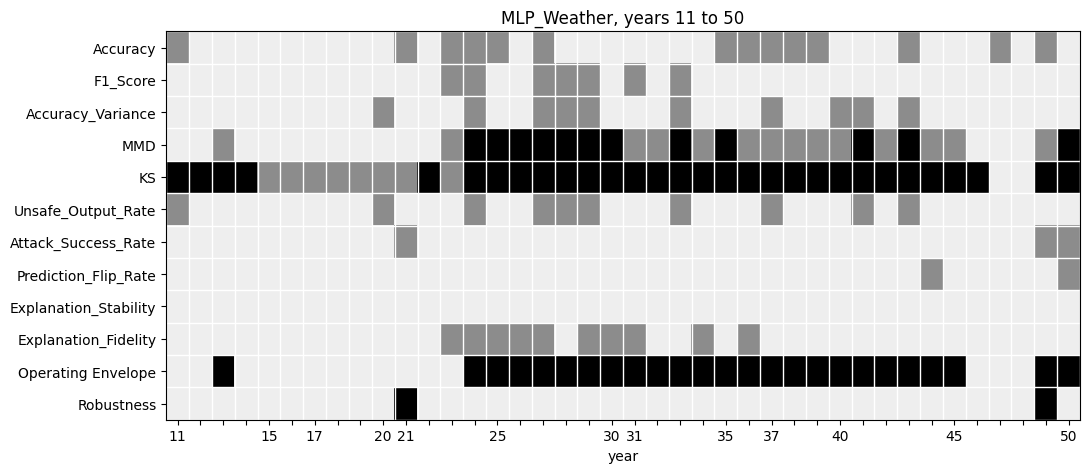

In [13]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def timeline(B, title):
    PLAN, yrs = B["K"]["PLAN"], B["years"]
    M = np.zeros((len(PLAN) + 2, len(yrs)))
    for i, s in enumerate(B["V_mon"]):
        for j, m in enumerate(PLAN):
            if s[j] > B["tau"][j]:
                M[j, i] = 2 if (m in ("MMD", "KS") and s[j] > B["tau_sev"][j]) else 1
        M[len(PLAN), i] = 2 if "OE" in B["mon_rows"][i]["debts"] else 0
        M[len(PLAN) + 1, i] = 2 if "Rob" in B["mon_rows"][i]["debts"] else 0
    fig, ax = plt.subplots(figsize=(11, 0.32 * (len(PLAN) + 2) + 1))
    ax.imshow(M, cmap=ListedColormap(["#eeeeee", "#8c8c8c", "#000000"]), vmin=0, vmax=2, aspect="auto")
    ax.set_yticks(range(len(PLAN) + 2)); ax.set_yticklabels(PLAN + ["Operating Envelope", "Robustness"])
    ax.set_xticks(range(len(yrs))); ax.set_xticklabels([str(t) if t % 5 == 0 or t in (11, 17, 21, 31, 37) else "" for t in yrs])
    ax.set_xticks(np.arange(-0.5, len(yrs)), minor=True); ax.set_yticks(np.arange(-0.5, len(PLAN) + 2), minor=True)
    ax.grid(which="minor", color="white", linewidth=1); ax.tick_params(which="minor", length=0)
    ax.set_xlabel("year"); ax.set_title(title)
    plt.tight_layout(); plt.show()

timeline(B, "MLP_Weather, years 11 to 50")

### The 40 years in five groups (Table V)

Each year falls into one group by what its metrics showed. The last three columns count the years of each group that each monitor flags.

In [14]:
def groups(B):
    j_acc = B["K"]["PLAN"].index("Accuracy")
    names = ["No metric degraded", "One metric degraded", "Several metrics, no debt", "Debt, accuracy normal", "Debt, accuracy degraded"]
    G = {n: [] for n in names}
    for r in B["mon_rows"]:
        if r["n"] == 0: k = 0
        elif r["debts"]: k = 4 if r["acc_degraded"] else 3
        else: k = 1 if r["n"] == 1 else 2
        G[names[k]].append(r)
    rows = [[n, len(v), ", ".join(str(r["year"]) for r in v), sum(r["acc_degraded"] for r in v),
             sum(r["n"] >= 1 for r in v), sum(bool(r["debts"]) for r in v)] for n, v in G.items()]
    t = pd.DataFrame(rows, columns=["group", "years", "which years", "accuracy alone", "any single metric", "two related metrics"])
    t.loc[len(t)] = ["All years", 40, "11 to 50", t["accuracy alone"].sum(), t["any single metric"].sum(), t["two related metrics"].sum()]
    return t

table5 = groups(B)
display(table5)

,group,years,which years,accuracy alone,any single metric,two related metrics
0,No metric degraded,1,48,0,0,0
1,One metric degraded,10,"12, 14, 15, 16, 17, 18, 19, 22, 46, 47",1,10,0
2,"Several metrics, no debt",3,"11, 20, 23",2,3,0
3,"Debt, accuracy normal",15,"13, 26, 28, 29, 30, 31, 32, 33, 34, 40, 41, 42...",0,15,15
4,"Debt, accuracy degraded",11,"21, 24, 25, 27, 35, 36, 37, 38, 39, 43, 49",11,11,11
5,All years,40,11 to 50,14,39,26


### The four years discussed in Section IV.E

Values in the form of the paper (accuracy in %, F1 score as F1), with the threshold of each metric.

In [15]:
def four_years(B):
    PLAN = B["K"]["PLAN"]
    cols = {"Threshold": [shown(m, v) for m, v in zip(PLAN, B["tau"])]}
    for t in (17, 21, 31, 37):
        cols["Year %d" % t] = [shown(m, v) for m, v in zip(PLAN, B["V_mon"][B["years"].index(t)])]
    t4 = pd.DataFrame(cols, index=PLAN).round(4)
    info = [B["mon_rows"][B["years"].index(t)] for t in (17, 21, 31, 37)]
    extra = pd.DataFrame([[r["n"] for r in info], [", ".join(r["attributes"]) or "none" for r in info],
                          [", ".join(r["debts"]) or "none" for r in info]],
                         index=["degraded metrics", "degraded attributes", "debt"], columns=t4.columns[1:])
    return t4, extra

t4, extra = four_years(B)
display(t4); display(extra)

,Threshold,Year 17,Year 21,Year 31,Year 37
Accuracy,77.2917,84.7222,76.3889,80.2778,72.2222
F1_Score,0.5185,0.7511,0.6047,0.5103,0.5283
Accuracy_Variance,0.0736,0.0210,0.0201,0.0682,0.0832
MMD,0.0690,0.0379,0.0357,0.1095,0.1021
KS,0.3212,0.3354,0.3277,0.4811,0.4791
Unsafe_Output_Rate,0.5957,0.3413,0.4298,0.5889,0.6190
Attack_Success_Rate,0.4056,0.3889,0.4250,0.2694,0.2917
Prediction_Flip_Rate,0.0833,0.0611,0.0583,0.0583,0.0806
Explanation_Stability,0.0110,0.0087,0.0083,0.0058,0.0070
Explanation_Fidelity,0.3564,0.3138,0.3095,0.4271,0.2668


,Year 17,Year 21,Year 31,Year 37
degraded metrics,1,3,4,5
degraded attributes,Reliability,"Correctness, Reliability, Security","Correctness, Reliability, Resilience, Transpar...","Correctness, Reliability, Resilience, Safety"
debt,none,Rob,OE,OE


### Every monitored year

`one_metric_only` marks a complete pattern that the rule refused because a single metric supported it.
`ruled_out` marks a complete pattern whose history event is not on record.

In [16]:
mon = pd.DataFrame([{"year": r["year"], "accuracy %": round(shown("Accuracy", B["V_mon"][i][0]), 1),
                     "degraded metrics": ", ".join(r["degraded"]), "debts": ", ".join(r["debts"]),
                     "one metric only": ", ".join(r["one_metric_only"]), "ruled out": ", ".join(r["ruled_out"])}
                    for i, r in enumerate(B["mon_rows"])])
display(mon)

,year,accuracy %,degraded metrics,debts,one metric only,ruled out
0,11,75.3,"Accuracy, KS, Unsafe_Output_Rate",,OE,CL
1,12,80.0,KS,,OE,
2,13,79.4,"MMD, KS",OE,,
3,14,78.1,KS,,OE,
4,15,77.5,KS,,,
5,16,77.5,KS,,,
6,17,84.7,KS,,,
7,18,83.3,KS,,,
8,19,84.2,KS,,,
9,20,77.8,"Accuracy_Variance, KS, Unsafe_Output_Rate",,,CL


### One metric versus two (Section IV.F, Table VI)

Validation counts are false alarms, because every validation year is normal.

In [17]:
def evidence(B):
    PLAN = B["K"]["PLAN"]
    j_acc, j_ks = PLAN.index("Accuracy"), PLAN.index("KS")
    def count(rows, V):
        return {"Accuracy alone": int((V[:, j_acc] > B["tau"][j_acc]).sum()),
                "KS alone": int((V[:, j_ks] > B["tau"][j_ks]).sum()),
                "Any one metric": sum(r["n"] >= 1 for r in rows),
                "Any two metrics": sum(r["n"] >= 2 for r in rows),
                "Debt from two related metrics": sum(bool(r["debts"]) for r in rows)}
    v, m = count(B["val_rows"], B["V_val"]), count(B["mon_rows"], B["V_mon"])
    out = pd.DataFrame({"Resampled %": {k: round(100 * x / len(B["V_val"]), 1) for k, x in v.items()},
                        "Years (of 40)": m})
    missed = sum(bool(r["debts"]) and not r["acc_degraded"] for r in B["mon_rows"])
    return out, missed

ev, missed = evidence(B)
display(ev)
print("years with a debt while accuracy stayed normal: %d of %d" % (missed, ev.loc["Debt from two related metrics", "Years (of 40)"]))

,Resampled %,Years (of 40)
Accuracy alone,6.2,14
KS alone,5.0,38
Any one metric,27.5,39
Any two metrics,11.6,29
Debt from two related metrics,2.9,26


years with a debt while accuracy stayed normal: 15 of 26


## 9. The same steps for LR_Weather

The same functions, with the knowledge of `LR_Weather` from the ontology. Q3 drops both explanation metrics, because they do not apply to a logistic regression.
This cell takes about two minutes.

plan: ['Accuracy', 'F1_Score', 'Accuracy_Variance', 'MMD', 'KS', 'Unsafe_Output_Rate', 'Attack_Success_Rate', 'Prediction_Flip_Rate']
training accuracy: 80.2%  (paper: 80.2%)


done in 28 s


MLP_Weather                LR_Weather              
                              Resampled % Years (of 40) Resampled % Years (of 40)
Accuracy alone                        6.2            14         4.8            20
KS alone                              5.0            38         5.0            38
Any one metric                       27.5            39        20.3            39
Any two metrics                      11.6            29        10.7            34
Debt from two related metrics         2.9            26         2.3            28

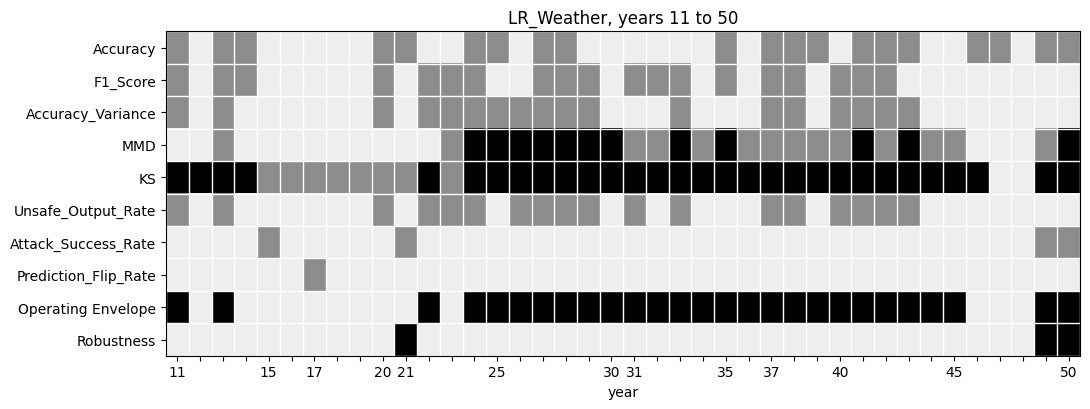

LR_Weather: years with a debt while accuracy stayed normal: 12


In [18]:
t0 = time.time()
K_lr = knowledge("LR_Weather")
B_lr = build(K_lr); B_lr["scores"] = make_scores(B_lr)
print("plan:", K_lr["PLAN"])
print("training accuracy: %.1f%%  (paper: 80.2%%)" % (100 * B_lr["model"].score(B_lr["Z"][B_lr["tr"]], y_all[B_lr["tr"]])))
B_lr["runs"], _, B_lr["tau"], B_lr["tau_sev"] = thresholds(B_lr)
validate_and_monitor(B_lr)
ev_lr, missed_lr = evidence(B_lr)
print("done in %.0f s" % (time.time() - t0))
display(pd.concat({"MLP_Weather": ev, "LR_Weather": ev_lr}, axis=1))
timeline(B_lr, "LR_Weather, years 11 to 50")
print("LR_Weather: years with a debt while accuracy stayed normal: %d" % missed_lr)

## 10. Trace the failure of year 21 in the ontology (Section IV.H, Fig. 3)

The static ontology never holds yearly values. `code/failure_path.py` copies the ontology and adds the record of one monitored year: one measurement for each degraded metric, linked to the model and the year.
Query Q12 follows each degraded measurement of year 21 to its metric, the attribute it degrades, and the documents that name that attribute, for the attributes that the Robustness debt requires.
The same query runs in the SPARQL Query tab of Protégé on `ontology/failure_path_MLP_Weather_year21.owl`.

In [19]:
demo = rdflib.Graph().parse(os.path.join(REPO, "ontology", "failure_path_MLP_Weather_year21.owl"), format="xml")
q12 = open(os.path.join(REPO, "queries", "Q12_failure_path.rq")).read()
print("Q12, Robustness debt of MLP_Weather in year 21:")
display(pd.DataFrame([[local(v) for v in r] for r in demo.query(q12)], columns=["metric", "attribute", "document"]))
print("Same query for Harmful Output (it also needs Safety, which did not degrade):")
display(pd.DataFrame([[local(v) for v in r] for r in demo.query(q12.replace("t:Robustness_Debt", "t:Harmful_Output"))],
                     columns=["metric", "attribute", "document"]))
i21, pl = B["years"].index(21), B["K"]["PLAN"]
for m in ("Accuracy", "Attack_Success_Rate", "Unsafe_Output_Rate"):
    j = pl.index(m)
    print("%-20s year 21: %.3f   threshold: %.3f   degraded: %s" % (m, shown(m, B["V_mon"][i21][j]), shown(m, B["tau"][j]),
                                                                       B["V_mon"][i21][j] > B["tau"][j]))

Q12, Robustness debt of MLP_Weather in year 21:


,metric,attribute,document
0,Accuracy,Correctness,EASA_ML_Concept_Paper
1,Accuracy,Correctness,EU_AI_Act
2,Accuracy,Correctness,NIST_AI_RMF
3,Attack_Success_Rate,Security,EASA_ML_Concept_Paper
4,Attack_Success_Rate,Security,EU_AI_Act
5,Attack_Success_Rate,Security,NIST_AI_RMF


Same query for Harmful Output (it also needs Safety, which did not degrade):


,metric,attribute,document
0,Attack_Success_Rate,Security,EASA_ML_Concept_Paper
1,Attack_Success_Rate,Security,EU_AI_Act
2,Attack_Success_Rate,Security,NIST_AI_RMF


Accuracy             year 21: 76.389   threshold: 77.292   degraded: True
Attack_Success_Rate  year 21: 0.425   threshold: 0.406   degraded: True
Unsafe_Output_Rate   year 21: 0.430   threshold: 0.596   degraded: False


## 11. Check against the paper

Every row compares a number computed above with the number printed in the paper (Sections IV.B to IV.F, Tables IV to VI).
A different scikit learn version can change the trained network slightly and shift a few values.

In [20]:
pl = B["K"]["PLAN"]; pl_lr = B_lr["K"]["PLAN"]
checks = [
    ("MLP training accuracy %", 83.8, 100 * B["model"].score(B["Z"][B["tr"]], y_all[B["tr"]])),
    ("LR training accuracy %", 80.2, 100 * B_lr["model"].score(B_lr["Z"][B_lr["tr"]], y_all[B_lr["tr"]])),
    ("MLP accuracy threshold %", 77.3, shown("Accuracy", B["tau"][pl.index("Accuracy")])),
    ("MLP KS threshold", 0.321, B["tau"][pl.index("KS")]),
    ("MLP unsafe output rate threshold", 0.596, B["tau"][pl.index("Unsafe_Output_Rate")]),
    ("MLP validation, accuracy alone %", 6.2, ev.loc["Accuracy alone", "Resampled %"]),
    ("LR validation, accuracy alone %", 4.8, ev_lr.loc["Accuracy alone", "Resampled %"]),
    ("MLP validation, any one metric %", 27.5, ev.loc["Any one metric", "Resampled %"]),
    ("MLP validation, debt %", 2.9, ev.loc["Debt from two related metrics", "Resampled %"]),
    ("LR validation, any one metric %", 20.3, ev_lr.loc["Any one metric", "Resampled %"]),
    ("LR validation, debt %", 2.3, ev_lr.loc["Debt from two related metrics", "Resampled %"]),
    ("MLP monitored years with a debt", 26, ev.loc["Debt from two related metrics", "Years (of 40)"]),
    ("MLP debt years with normal accuracy", 15, missed),
    ("Table V, years with one metric degraded", 10, table5.loc[1, "years"]),
    ("Table V, years with several metrics and no debt", 3, table5.loc[2, "years"]),
    ("LR monitored years with a debt", 28, ev_lr.loc["Debt from two related metrics", "Years (of 40)"]),
    ("LR debt years with normal accuracy", 12, missed_lr),
]
res = pd.DataFrame(checks, columns=["quantity", "paper", "this notebook"])
res["this notebook"] = res["this notebook"].astype(float).round(3)
def decimals(p):
    t = repr(p)
    return len(t.split(".")[1]) if "." in t else 0
res["match"] = [round(n, decimals(p)) == p for p, n in zip(res["paper"], res["this notebook"])]
display(res)

,quantity,paper,this notebook,match
0,MLP training accuracy %,83.800,83.833,True
1,LR training accuracy %,80.200,80.167,True
2,MLP accuracy threshold %,77.300,77.292,True
3,MLP KS threshold,0.321,0.321,True
4,MLP unsafe output rate threshold,0.596,0.596,True
5,"MLP validation, accuracy alone %",6.200,6.200,True
6,"LR validation, accuracy alone %",4.800,4.800,True
7,"MLP validation, any one metric %",27.500,27.500,True
8,"MLP validation, debt %",2.900,2.900,True
9,"LR validation, any one metric %",20.300,20.300,True


## 12. Try it yourself

* Change `K["S"]["trainTo"]` (training years) or `K["S"]["resampleSizes"]` before Section 3, then rerun from there. The results will no longer match the paper.
* Compare the monitored years of both models: `mon` holds the network; build the same table from `B_lr["mon_rows"]`.
* Open `IEEESyscon_2027/ontology/trustworthiness_debt.owl` in Protégé and paste any file from `queries/` into the SPARQL Query tab to see the same answers as Section 2.